# How much history should measure cash-flow variability?

Compare **26 complete weeks**, **52 complete weeks**, and **all available complete weeks** for estimating later weekly gross-fee variability. Each cutoff uses exactly the same revenue-only top 100 and the same eligible universe for covariance estimation. Expected monthly gross fees and merchant selection do not change.

Raw sample covariance and diagonal-preserving shrinkage are evaluated separately. This tests the lookback for the existing risk definition; it does not compare detrended/downside risk or optimize a portfolio.

## Fixed comparison protocol

**Primary comparison:** February-June 2022, the five original evaluation cutoffs with at least 52 complete weeks. All history ranges from 52 to 69 weeks. At the first cutoff, 52 weeks and all history are identical. **Secondary comparison:** 26 weeks versus all history over all eight November 2021-June 2022 cutoffs. Do not compare averages from these different sets of dates as if they were matched.

**Outcome:** sample standard deviation of the fixed portfolio's weekly fees in complete Monday-Sunday weeks wholly inside the next three calendar months (11-13 observations). The primary error is absolute estimated-minus-observed SD, averaged equally over cutoffs. Report signed error and underestimation frequency/amount as well.

All-history starts with the week of 1-7 March 2021. Genuine zero-sales weeks remain; partial boundary weeks are excluded. Shrinkage is refitted for each history using the unchanged standardized Ledoit-Wolf procedure and the same eligible merchants. Every estimate is saved before future outcomes are attached. Outcomes have been examined previously, so this is retrospective research, not a fresh holdout.

## Reproduce

Use the existing requirements-forecast.txt environment. The audited daily panel, monthly panel and cash-flow baseline outputs must exist. No GPU, model download or network access is required.

```text
python code/scripts/cash_flow_lookback_comparison.py
python -m pytest -p no:capture code/tests/test_cash_flow_lookback_comparison.py -q
```

The next cell runs the complete comparison. Existing 26-week feature outputs remain unchanged.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display, Markdown

here = Path.cwd()
ROOT = next(p for p in [here, *here.parents] if (p / "code/scripts/cash_flow_lookback_comparison.py").exists())
sys.path.insert(0, str(ROOT / "code/scripts"))
import cash_flow_lookback_comparison as comparison

scored, primary, secondary = comparison.run()

Estimating all lookbacks at 2021-11-30


Estimating all lookbacks at 2021-12-31


Estimating all lookbacks at 2022-01-31


Estimating all lookbacks at 2022-02-28


Estimating all lookbacks at 2022-03-31


...

Estimating all lookbacks at 2022-05-31


Estimating all lookbacks at 2022-06-30


Estimating all lookbacks at 2022-09-30


PRIMARY: identical five origins
estimator window  origins  mean_absolute_error  mean_signed_error  underestimate_count  mean_underestimate_amount  worst_underestimate_amount  wins_vs_26w  ties_vs_26w  mae_improvement_vs_26w_pct
   sample    26w        5            72884.877          72884.877                    0                        0.0                         0.0            0            5                       0.000
   sample    52w        5            63995.091          63995.091                    0                        0.0                         0.0            4            0                      12.197
   sample    all        5            62681.277          62681.277                    0                        0.0                         0.0            4            0                      14.000
   shrunk    26w        5            51945.297          51945.297                    0                        0.0                         0.0            0            5                 

SECONDARY: identical eight origins
estimator window  origins  mean_absolute_error  mean_signed_error  underestimate_count  mean_underestimate_amount  worst_underestimate_amount  wins_vs_26w  ties_vs_26w  mae_improvement_vs_26w_pct
   sample    26w        8            65433.187          60930.784                    1                   2251.201                   18009.612            0            8                       0.000
   sample    all        8            57128.254          51628.386                    1                   2749.934                   21999.473            6            0                      12.692
   shrunk    26w        8            50931.179          37227.928                    1                   6851.625                   54813.004            0            8                       0.000
   shrunk    all        8            47062.451          34825.760                    1                   6118.346                   48946.765            5            0              

## Matched primary results

All six rows use the same five origins and the same future targets. A lower estimate is not automatically better: its distance from later observed volatility determines the error. Mean underestimation includes zero for origins that overestimate risk.

,estimator,window,origins,mean_absolute_error,mean_signed_error,underestimate_count,mean_underestimate_amount,worst_underestimate_amount,wins_vs_26w,ties_vs_26w,mae_improvement_vs_26w_pct
0,sample,26w,5,72884.876723,72884.876723,0,0.0,0.0,0,5,0.000000
1,sample,52w,5,63995.090508,63995.090508,0,0.0,0.0,4,0,12.197024
2,sample,all,5,62681.277187,62681.277187,0,0.0,0.0,4,0,13.999611
3,shrunk,26w,5,51945.297315,51945.297315,0,0.0,0.0,0,5,0.000000
4,shrunk,52w,5,47765.197909,47765.197909,0,0.0,0.0,3,0,8.047118
5,shrunk,all,5,48136.913376,48136.913376,0,0.0,0.0,3,0,7.331528


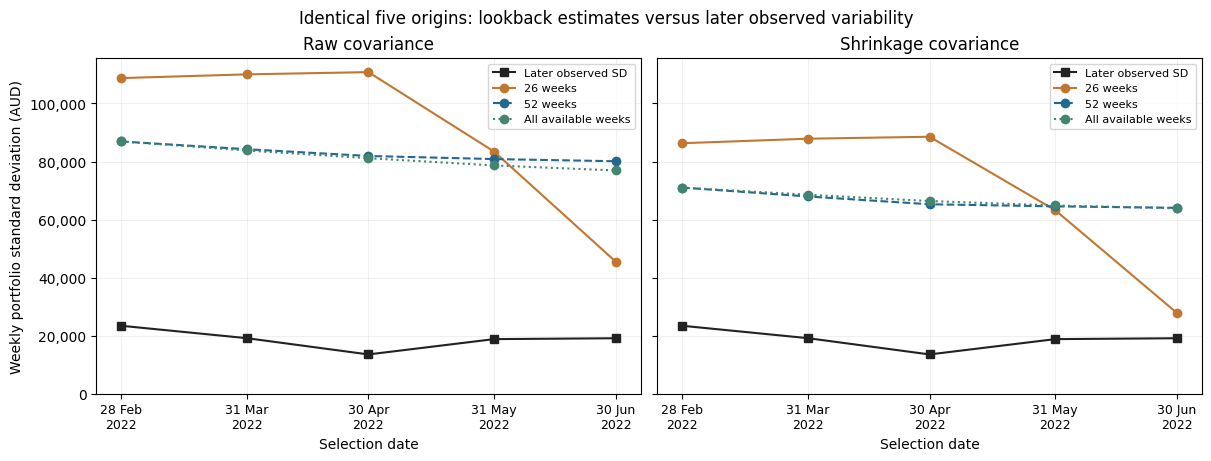

In [2]:
display(primary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, layout="constrained")
colors = {"26w": "#c17730", "52w": "#236891", "all": "#438571"}
styles = {"26w": "-", "52w": "--", "all": ":"}
common = pd.date_range("2022-02-28", "2022-06-30", freq="ME")
for ax, estimator in zip(axes, ["sample", "shrunk"]):
    data = scored.loc[scored.as_of.isin(common) & scored.estimator.eq(estimator)]
    observed = data.drop_duplicates("as_of").sort_values("as_of")
    ax.plot(observed.as_of, observed.actual_weekly_sd, color="#222222", marker="s", label="Later observed SD")
    for window in comparison.WINDOWS:
        line = data.loc[data.window.eq(window)].sort_values("as_of")
        ax.plot(line.as_of, line.estimated_weekly_sd, marker="o", linestyle=styles[window], color=colors[window],
                label=comparison.LABELS[window])
    ax.set(title="Raw covariance" if estimator == "sample" else "Shrinkage covariance", xlabel="Selection date", ylim=(0, None))
    ax.set_xticks(common)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Y"))
    ax.tick_params(axis="x", rotation=0, labelsize=9)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(alpha=.18)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Weekly portfolio standard deviation (AUD)")
fig.suptitle("Identical five origins: lookback estimates versus later observed variability")
fig.savefig(comparison.OUT / "lookback_comparison.png", dpi=160)
plt.show()

## Broader and non-overlapping checks

The secondary table adds earlier dates for which a 52-week estimate was impossible. Non-overlapping schedules reduce direct overlap in outcome months, but contain only two, two and one primary origins. They do not establish statistical significance.

In [3]:
display(secondary)
display(pd.read_parquet(comparison.OUT / "nonoverlapping_schedules.parquet"))
availability = pd.read_parquet(comparison.OUT / "availability.parquet")
display(availability.pivot(index="as_of", columns="window", values="available"))

,estimator,window,origins,mean_absolute_error,mean_signed_error,underestimate_count,mean_underestimate_amount,worst_underestimate_amount,wins_vs_26w,ties_vs_26w,mae_improvement_vs_26w_pct
0,sample,26w,8,65433.187335,60930.784382,1,2251.201477,18009.611814,0,8,0.000000
1,sample,all,8,57128.254397,51628.386239,1,2749.934079,21999.472635,6,0,12.692234
2,shrunk,26w,8,50931.179107,37227.928131,1,6851.625488,54813.003903,0,8,0.000000
3,shrunk,all,8,47062.450861,34825.759523,1,6118.345669,48946.765349,5,0,7.595992


,estimator,window,origins,mean_absolute_error,mean_signed_error,underestimate_count,mean_underestimate_amount,worst_underestimate_amount,wins_vs_26w,ties_vs_26w,mae_improvement_vs_26w_pct,schedule,cutoffs
0,sample,26w,2,74959.411485,74959.411485,0,0.0,0.0,0,2,0.000000,0,"2022-02-28, 2022-05-31"
1,sample,52w,2,62763.240096,62763.240096,0,0.0,0.0,2,0,16.270367,0,"2022-02-28, 2022-05-31"
2,sample,all,2,61663.415470,61663.415470,0,0.0,0.0,2,0,17.737594,0,"2022-02-28, 2022-05-31"
3,shrunk,26w,2,53645.364482,53645.364482,0,0.0,0.0,0,2,0.000000,0,"2022-02-28, 2022-05-31"
4,shrunk,52w,2,46669.472577,46669.472577,0,0.0,0.0,1,0,13.003718,0,"2022-02-28, 2022-05-31"
5,shrunk,all,2,46825.889191,46825.889191,0,0.0,0.0,1,0,12.712143,0,"2022-02-28, 2022-05-31"
6,sample,26w,2,58620.320968,58620.320968,0,0.0,0.0,0,2,0.000000,1,"2022-03-31, 2022-06-30"
7,sample,52w,2,63038.445357,63038.445357,0,0.0,0.0,1,0,-7.536848,1,"2022-03-31, 2022-06-30"
8,sample,all,2,61233.763894,61233.763894,0,0.0,0.0,1,0,-4.458254,1,"2022-03-31, 2022-06-30"
9,shrunk,26w,2,38718.180858,38718.180858,0,0.0,0.0,0,2,0.000000,1,"2022-03-31, 2022-06-30"


window,26w,52w,all
as_of,,,
2021-11-30,True,False,True
2021-12-31,True,False,True
2022-01-31,True,False,True
2022-02-28,True,True,True
2022-03-31,True,True,True
2022-04-30,True,True,True
2022-05-31,True,True,True
2022-06-30,True,True,True
2022-09-30,True,True,True


## Latest estimates and validation

September 2022 has enough history for all three methods but lacks a complete subsequent quarter in the audited panel. These estimates are not scored and do not affect comparison results. The existing merchant volatility feature continues to use 26 weeks; this experiment records evidence without silently changing it.

In [4]:
display(scored.loc[scored.as_of.eq(pd.Timestamp("2022-09-30")),
    ["window", "estimator", "history_weeks", "history_start", "history_end", "estimated_weekly_sd", "shrinkage_alpha", "status"]])
display(json.loads((comparison.OUT / "acceptance_checks.json").read_text()))
display(Markdown((comparison.OUT / "findings.md").read_text(encoding="utf-8")))

,window,estimator,history_weeks,history_start,history_end,estimated_weekly_sd,shrinkage_alpha,status
42,26w,sample,26,2022-03-28,2022-09-25,29216.121623,0.830553,insufficient_complete_outcome_period
43,26w,shrunk,26,2022-03-28,2022-09-25,13167.757759,0.830553,insufficient_complete_outcome_period
44,52w,sample,52,2021-09-27,2022-09-25,80189.919356,0.343436,insufficient_complete_outcome_period
45,52w,shrunk,52,2021-09-27,2022-09-25,65234.370892,0.343436,insufficient_complete_outcome_period
46,all,sample,82,2021-03-01,2022-09-25,74563.106593,0.271527,insufficient_complete_outcome_period
47,all,shrunk,82,2021-03-01,2022-09-25,63823.263955,0.271527,insufficient_complete_outcome_period


{'audited_inputs_and_complete_weeks': True,
 'baseline_reproductions': 9,
 'unchanged_26w_estimates': 9,
 'independent_future_outcomes': 8,
 'future_transaction_perturbations': 8,
 'matched_primary_origins': 5,
 'matched_secondary_origins': 8,
 'reproducible_rerun': False,
 'digests': {'estimates': '2ce130d1847ae8fe90dc27359383ba406ac64dee077c5949458b05b4de358562',
  'scored': 'c22e5564b969d3f3baf6f2834548bded2009326651792db6bd74a83312ee46a0',
  'primary': '950b3b689101371a1021e4b3131edb6e33a7e86389c7cef4e137e43d08e670d1',
  'secondary': '434267889244b0e2fbc1dbee4993fcf21b6aac7ccdf1cd6fc9fc2a8acf9339bb'}}

# Cash-flow variability: 26 weeks, 52 weeks or all history?

The primary comparison uses the same five cutoffs, February-June 2022, and the same revenue-only top 100 at each cutoff. The target is sample SD of their later weekly gross fees in complete weeks within the following three calendar months. Lower error means closer to this later observed statistic, not proven accuracy for an unobserved population risk parameter.

## Primary matched comparison

| Covariance | History | Origins | Mean absolute SD error (AUD) | Mean signed error (AUD) | Underestimates | Mean underestimation (AUD) | Wins vs 26 weeks |
|---|---|---:|---:|---:|---:|---:|---:|
| sample | 26 weeks | 5 | 72,884.88 | +72,884.88 | 0/5 | 0.00 | 0 |
| sample | 52 weeks | 5 | 63,995.09 | +63,995.09 | 0/5 | 0.00 | 4 |
| sample | All available weeks | 5 | 62,681.28 | +62,681.28 | 0/5 | 0.00 | 4 |
| shrunk | 26 weeks | 5 | 51,945.30 | +51,945.30 | 0/5 | 0.00 | 0 |
| shrunk | 52 weeks | 5 | 47,765.20 | +47,765.20 | 0/5 | 0.00 | 3 |
| shrunk | All available weeks | 5 | 48,136.91 | +48,136.91 | 0/5 | 0.00 | 3 |

Mean underestimation includes zero for origins that overestimate risk. Positive signed error means overestimation. The target is identical across windows; raw and shrinkage methods are compared separately.

For sample covariance, the lowest observed mean absolute error is **All available weeks** (A$62,681.28). This is a descriptive result from these five dates.
For shrunk covariance, the lowest observed mean absolute error is **52 weeks** (A$47,765.20). This is a descriptive result from these five dates.

Every method overestimated later SD at all five common cutoffs. Longer histories reduced average error, but did not resolve the substantial overestimation. With shrinkage, 26 weeks was closer than both longer windows in May and June; conclusions also differ across the non-overlapping schedules. There is no consistently best lookback across all dates and estimators.

Treat 52 weeks as the lowest-MAE shrinkage candidate in this comparison and all history as the lowest-MAE raw-covariance candidate. Keep the existing 26-week feature as the documented baseline and report the alternatives as sensitivity results; this evidence does not establish an optimal window.

## Secondary comparison on all eight earlier cutoffs

52 weeks are unavailable in November 2021-January 2022. Compare only 26 weeks and all history here; do not rank these eight-origin averages against the five-origin averages above.

| Covariance | History | Mean absolute SD error (AUD) | Underestimates | Mean underestimation (AUD) | Wins vs 26 weeks |
|---|---|---:|---:|---:|---:|
| sample | 26 weeks | 65,433.19 | 1/8 | 2,251.20 | 0 |
| sample | All available weeks | 57,128.25 | 1/8 | 2,749.93 | 6 |
| shrunk | 26 weeks | 50,931.18 | 1/8 | 6,851.63 | 0 |
| shrunk | All available weeks | 47,062.45 | 1/8 | 6,118.35 | 5 |

## Every scored origin

| Cutoff | History | Past weeks | Future weeks | Later SD (AUD) | Raw estimate (AUD) | Shrunk estimate (AUD) |
|---|---|---:|---:|---:|---:|---:|
| 2021-11-30 | 26 weeks | 26 | 12 | 97,613.09 | 79,603.47 | 42,800.08 |
| 2021-11-30 | All available weeks | 39 | 12 | 97,613.09 | 75,613.61 | 48,666.32 |
| 2021-12-31 | 26 weeks | 26 | 12 | 29,488.54 | 95,607.54 | 70,858.44 |
| 2021-12-31 | All available weeks | 43 | 12 | 29,488.54 | 90,547.97 | 72,524.99 |
| 2022-01-31 | 26 weeks | 26 | 11 | 28,312.35 | 103,224.85 | 79,852.39 |
| 2022-01-31 | All available weeks | 48 | 11 | 28,312.35 | 88,873.10 | 72,144.17 |
| 2022-02-28 | 26 weeks | 26 | 12 | 23,419.32 | 108,741.52 | 86,304.66 |
| 2022-02-28 | 52 weeks | 52 | 12 | 23,419.32 | 86,910.68 | 71,020.46 |
| 2022-02-28 | All available weeks | 52 | 12 | 23,419.32 | 86,910.68 | 71,020.46 |
| 2022-03-31 | 26 weeks | 26 | 12 | 19,142.79 | 110,027.49 | 87,863.99 |
| 2022-03-31 | 52 weeks | 52 | 12 | 19,142.79 | 84,236.18 | 67,954.94 |
| 2022-03-31 | All available weeks | 56 | 12 | 19,142.79 | 83,801.26 | 68,556.22 |
| 2022-04-30 | 26 weeks | 26 | 13 | 13,537.49 | 110,802.41 | 88,536.89 |
| 2022-04-30 | 52 weeks | 52 | 13 | 13,537.49 | 81,909.57 | 65,277.98 |
| 2022-04-30 | All available weeks | 60 | 13 | 13,537.49 | 81,149.52 | 66,383.67 |
| 2022-05-31 | 26 weeks | 26 | 12 | 18,810.70 | 83,407.32 | 63,216.09 |
| 2022-05-31 | 52 weeks | 52 | 12 | 18,810.70 | 80,845.82 | 64,548.50 |
| 2022-05-31 | All available weeks | 65 | 12 | 18,810.70 | 78,646.17 | 64,861.34 |
| 2022-06-30 | 26 weeks | 26 | 12 | 19,113.58 | 45,469.51 | 27,828.73 |
| 2022-06-30 | 52 weeks | 52 | 12 | 19,113.58 | 80,097.08 | 64,047.98 |
| 2022-06-30 | All available weeks | 69 | 12 | 19,113.58 | 76,922.63 | 63,886.75 |

## Interpretation and limits

All-history means complete weeks beginning 1 March 2021, ending before or on each cutoff. It ranges from 52 to 69 weeks in the primary comparison. At February 2022, 52 weeks and all history are exactly the same observations; they are not independent alternatives at that date.

The three schedules of non-overlapping future quarters are exported separately. They contain only two, two and one primary origins; the five overlapping results are not five independent macroeconomic replications. Every future SD itself uses only 11-13 weeks and is noisy. Synthetic data, retained trends and calendar effects, and previously examined outcomes limit interpretation. There is no fresh holdout, statistical-significance claim or evidence of improved portfolio selection.

September 2022 estimates are exported for reference but have no complete future quarter and are excluded from all error summaries. Expected return, eligibility and merchant selection stay fixed. This experiment does not overwrite the existing 26-week feature or optimize a portfolio.

Reproduce: `python code/scripts/cash_flow_lookback_comparison.py`. Tests: `python -m pytest -p no:capture code/tests/test_cash_flow_lookback_comparison.py -q`. The notebook 05_cash_flow_lookback_comparison.ipynb explains the comparison. Outputs are ignored uncompressed Parquet and CSV under tables/analysis/cash_flow_lookback_comparison.


## Interpretation boundary

A window that wins here is an observed error winner for these fixed portfolios and dates, not a universally optimal risk estimator. Future SD is itself noisy, and growth/seasonality remain in both historical and future measurements. A covariance estimate that works for these portfolios may behave differently after optimization changes the selected merchants.

The experiment uses synthetic data, short history and previously examined outcomes. It does not establish independent macroeconomic replications, causal effects, credit-loss predictions or improved risk-aware merchant selection.